### Data yang digunakan adalah Healthcare Real-Time Risk Dataset yang bisa diakses di Kaggle melalui link ini (https://www.kaggle.com/datasets/alekhyaabburi/healthcare). Data ini mencakup 1000 pasien dengan 10 variabel fitur yang termasuk termasuk usia, jenis kelamin, BMI, status merokok, konsumsi alkohol, aktivitas fisik, durasi tidur, penyakit kronis, tingkat stres, dan tingkat risiko kesehatan. Variabel respon yang digunakan adalah tingkat stres dan variabel prediktor adalah konsumsi alkohol, aktivitas fisik, dan durasi tidur dalam analisis CCA.

# Langkah 1: Preprocessing Data

In [1]:
import numpy as np
import pandas as pd

In [2]:
from google.colab import files
files.upload()

Saving df_healthcare.xlsx to df_healthcare.xlsx


{'df_healthcare.xlsx': b'PK\x03\x04\x14\x00\x06\x00\x08\x00\x00\x00!\x00NDF\xef\xa1\x01\x00\x00/\x07\x00\x00\x13\x00\x08\x02[Content_Types].xml \xa2\x04\x02(\xa0\x00\x02\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x0

In [3]:
# Load Dataset
df = pd.read_excel("df_healthcare.xlsx")
df

,Age,Gender,BMI,Smoking Status,Alcohol Consumption (per week),Physical Activity (hours/week),Sleep Duration (hours/day),Chronic Disease History,Stress Level (1-10),Health Risk Level
0,56,Other,2315,Never,1,1,49,Heart Disease,5,High
1,69,Male,2083,Former,3,98,72,NaN,8,Moderate
2,46,Female,2155,Never,0,97,54,Hypertension,7,Low
3,32,Other,2747,Former,18,40,48,Hypertension,8,Low
4,60,Male,2709,Current,9,73,59,Diabetes,8,High
...,...,...,...,...,...,...,...,...,...,...
995,18,Other,1908,Never,19,21,45,Diabetes,8,Moderate
996,35,Other,1686,Former,5,74,73,NaN,5,Moderate
997,49,Female,3136,Never,15,55,69,Heart Disease,8,High
998,64,Other,3446,Current,2,88,72,Diabetes,3,High


# Langkah 2: Bagi dataset menjadi dua

In [23]:
# Definisikan variabel X dan Y
X = df[['Alcohol Consumption (per week)', 'Physical Activity (hours/week)', 'Sleep Duration (hours/day)']]
Y = df[['Stress Level (1-10)']]

# Gabungankan dan hitung korelas
combined = pd.concat([X, Y], axis=1)
corr = combined.corr()

cross_corr = corr.loc[X.columns, Y.columns]
print(cross_corr.round(3))

                                Stress Level (1-10)
Alcohol Consumption (per week)               -0.048
Physical Activity (hours/week)                0.025
Sleep Duration (hours/day)                    0.056


# Langkah 3: Standarisasi Data

In [6]:
from sklearn.preprocessing import StandardScaler

scaler_x = StandardScaler()
scaler_y = StandardScaler()
X_scaled = scaler_x.fit_transform(X)
Y_scaled = scaler_y.fit_transform(Y)

# Langkah 4: Lakukan fit CCA

In [24]:
from sklearn.cross_decomposition import CCA

cca = CCA(n_components=1,
      scale=False,
      max_iter=1000)

U, V = cca.fit_transform(X_scaled, Y_scaled)

print(U.shape)
print(V.shape)

(1000, 1)
(1000, 1)


# Langkah 5: Hitung Canonical Correlations

In [25]:
canonical_correlations = []
for i in range(1):
    r = np.corrcoef(U[:, i], V[:, i])[0, 1]
    canonical_correlations.append(r)

for i, r in enumerate(canonical_correlations, start=1):
    print(f"Canonical Correlation {i}: {r:.3f}")

Canonical Correlation 1: 0.096


# Langkah 6: Tentukan Weights & Loadings dari Output CCA

In [29]:
x_weights = pd.DataFrame(
    cca.x_weights_,
    index=X.columns,
    columns=["CV1"])
print(x_weights.round(1))

y_weights = pd.DataFrame(
    cca.y_weights_,
    index=Y.columns,
    columns=["CV1"])
print(y_weights.round(1))

                                CV1
Alcohol Consumption (per week) -0.6
Physical Activity (hours/week)  0.3
Sleep Duration (hours/day)      0.7
                     CV1
Stress Level (1-10)  1.0


# Langkah 7: Visualisasi data

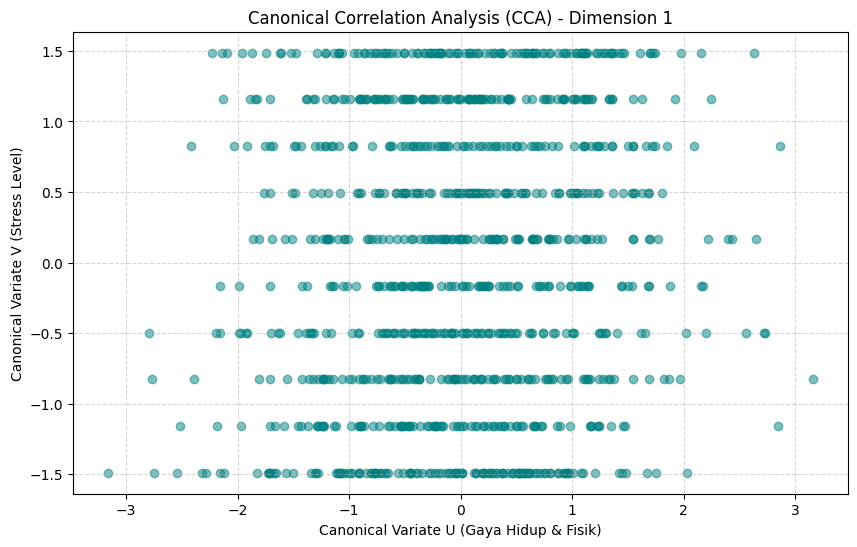

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.scatter(U[:, 0], V[:, 0], alpha=0.5, color='teal')
plt.title("Canonical Correlation Analysis (CCA) - Dimension 1")
plt.xlabel("Canonical Variate U (Gaya Hidup & Fisik)")
plt.ylabel("Canonical Variate V (Stress Level)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()



### Kesimpulan: Kesimpulan: Berdasarkan hasil di atas, disimpulkan bahwa variabel gaya hidup dan kondisi fisik (durasi tidur, konsumsi alkohol, dan aktivitas fisik) secara simultan memiliki hubungan linear yang sangat lemah (hampir tidak berpengaruh signifikan) terhadap tingkat stres seseorang.